# The world's airline network, in plain SQL

**3,425 airports and 67,663 airline routes** from the OpenFlights database, a snapshot of the schedules of about 2014 (the route file was last changed in 2017, so read it as a picture of a past network, not of today's). A route map is a **graph**, and SQL can treat it as one: degrees with `COUNT(DISTINCT ...)`, concentration with a running `SUM()` over a ranking, distances from latitude and longitude with the **haversine formula** written as a SQL expression, and, above all, **recursive CTEs** that walk the network: how many airports can you reach in one, two, three flights, and what is the shortest itinerary from Warsaw to Easter Island. The last section audits the data itself, because the source has some traps (two airlines that share one code, routes pointing at airports that are not in the airport list).

Python only runs the queries and draws the charts.

In [1]:
import os
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = Path(os.environ.get("OPENFLIGHTS_DB", "openflights.db"))
BLUE, AMBER, GREY, RED = "#2b6cb0", "#e8a33d", "#a0aec0", "#c0392b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

con = sqlite3.connect(DB_PATH)


def q(sql):
    """Run a query and return the result as a DataFrame."""
    return pd.read_sql_query(sql, con)

## 0. What is in the database?

In [2]:
tables = q("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name").name
pd.DataFrame({"table": tables,
              "rows": [con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tables]})

,table,rows
0,airlines,6162
1,airports,7698
2,routes,67663


## 1. Which airports have the most destinations?

The number of different airports you can fly to non-stop is the **degree** of an airport in the network. `SELECT DISTINCT` first collapses the airlines (a pair flown by three airlines counts once), then `RANK()` orders the airports.

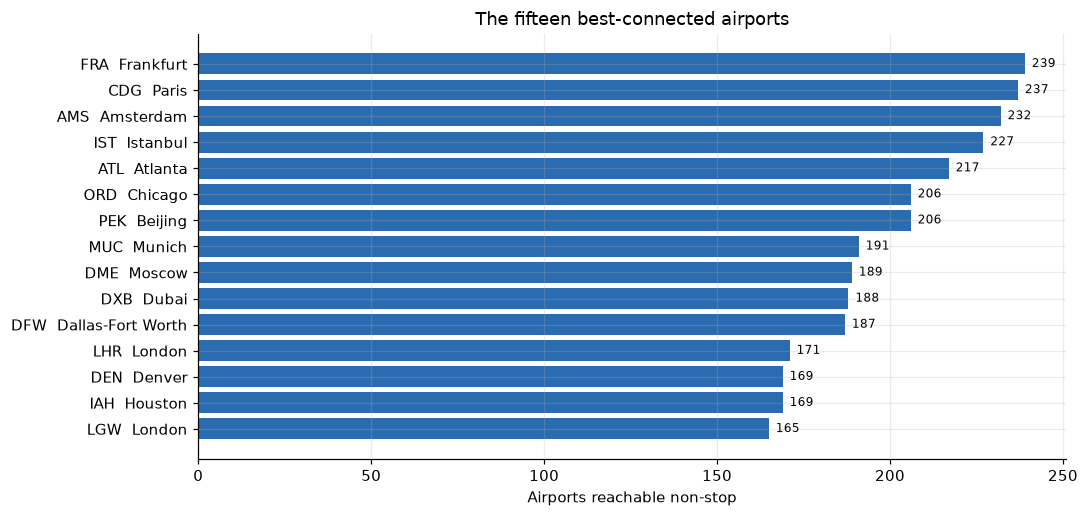

,airport_rank,iata,city,country,destinations
0,1,FRA,Frankfurt,Germany,239
1,2,CDG,Paris,France,237
2,3,AMS,Amsterdam,Netherlands,232
3,4,IST,Istanbul,Turkey,227
4,5,ATL,Atlanta,United States,217
5,6,ORD,Chicago,United States,206
6,6,PEK,Beijing,China,206
7,8,MUC,Munich,Germany,191
8,9,DME,Moscow,Russia,189
9,10,DXB,Dubai,United Arab Emirates,188


In [3]:
hubs = q("""
WITH pairs AS (
    SELECT DISTINCT src, dst FROM routes
)
SELECT RANK() OVER (ORDER BY COUNT(*) DESC) AS airport_rank,
       p.src AS iata, a.city, a.country, COUNT(*) AS destinations
FROM pairs p
JOIN airports a ON a.iata = p.src
GROUP BY p.src, a.city, a.country
ORDER BY destinations DESC, iata
LIMIT 15
""")

top = hubs.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh([f"{i}  {c}" for i, c in zip(top.iata, top.city)], top.destinations, color=BLUE)
for y, v in enumerate(top.destinations):
    ax.text(v + 2, y, v, va="center", fontsize=8)
ax.set_xlabel("Airports reachable non-stop")
ax.set_title("The fifteen best-connected airports")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

hubs

## 2. How unequal is the network?

A running `SUM()` over the airports ordered from most to least connected, divided by the total, shows what share of all airport pairs the busiest airports hold. `ROW_NUMBER()` over the airport count gives the share of airports.

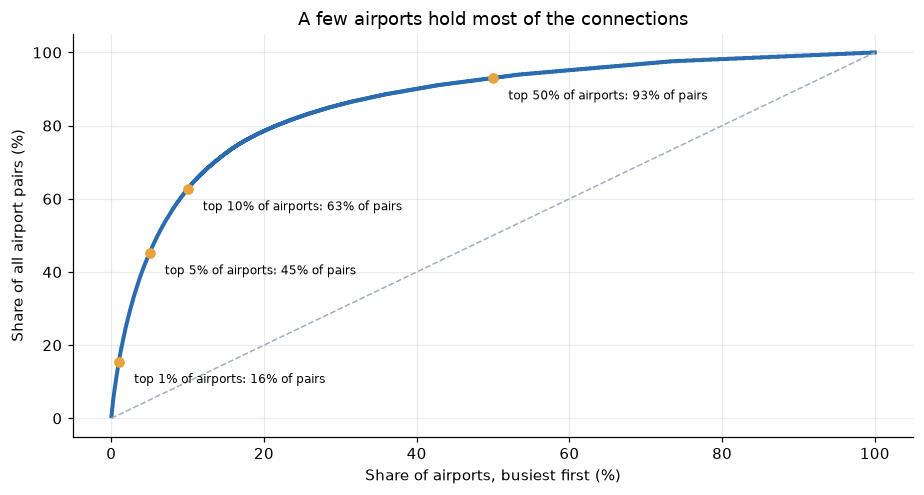

,airport_rank,iata,destinations,airport_pct,route_share_pct
33,34,DTW,135,1.00,15.5
169,170,SGN,54,4.99,45.1
340,341,DTM,28,10.00,62.7
851,852,MJT,8,24.99,82.6
1703,1704,PQQ,3,49.99,93.0


In [4]:
concentration = q("""
WITH d AS (
    SELECT src AS iata, COUNT(DISTINCT dst) AS destinations FROM routes GROUP BY src
),
r AS (
    SELECT iata, destinations,
           ROW_NUMBER() OVER (ORDER BY destinations DESC, iata)                                          AS airport_rank,
           COUNT(*) OVER ()                                                                              AS airports,
           SUM(destinations) OVER (ORDER BY destinations DESC, iata ROWS UNBOUNDED PRECEDING)           AS running,
           SUM(destinations) OVER ()                                                                     AS total_pairs
    FROM d
)
SELECT airport_rank, iata, destinations,
       ROUND(100.0 * airport_rank / airports, 2) AS airport_pct,
       ROUND(100.0 * running / total_pairs, 1)   AS route_share_pct
FROM r
ORDER BY airport_rank
""")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(concentration.airport_pct, concentration.route_share_pct, color=BLUE, lw=2.6)
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
for p in (1, 5, 10, 50):
    r = concentration[concentration.airport_pct >= p].iloc[0]
    ax.scatter([r.airport_pct], [r.route_share_pct], color=AMBER, zorder=3)
    ax.annotate(f"top {p}% of airports: {r.route_share_pct:.0f}% of pairs", (r.airport_pct, r.route_share_pct), xytext=(10, -14), textcoords="offset points", fontsize=8)
ax.set_xlabel("Share of airports, busiest first (%)")
ax.set_ylabel("Share of all airport pairs (%)")
ax.set_title("A few airports hold most of the connections")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

concentration[concentration.airport_rank.isin([34, 170, 341, 852, 1704])]

## 3. How many airports are tiny?

A conditional count on the same degree table: airports with a single destination, with three or fewer, and the big hubs with 100 or more.

In [5]:
sizes = q("""
WITH d AS (
    SELECT src AS iata, COUNT(DISTINCT dst) AS destinations FROM routes GROUP BY src
)
SELECT COUNT(*)                         AS airports_with_departures,
       SUM(destinations = 1)            AS one_destination,
       SUM(destinations <= 3)           AS three_or_fewer,
       SUM(destinations >= 100)         AS hundred_or_more,
       ROUND(AVG(destinations), 1)      AS average,
       MAX(destinations)                AS most
FROM d
""")

sizes

,airports_with_departures,one_destination,three_or_fewer,hundred_or_more,average,most
0,3409,906,1949,64,11.0,239


## 4. Which countries fly mostly at home?

Each airport pair is tagged with the countries of its two ends (a self-join of the airport table through two `JOIN`s), and a conditional sum gives the domestic share. Only countries with at least 500 departing pairs are shown.

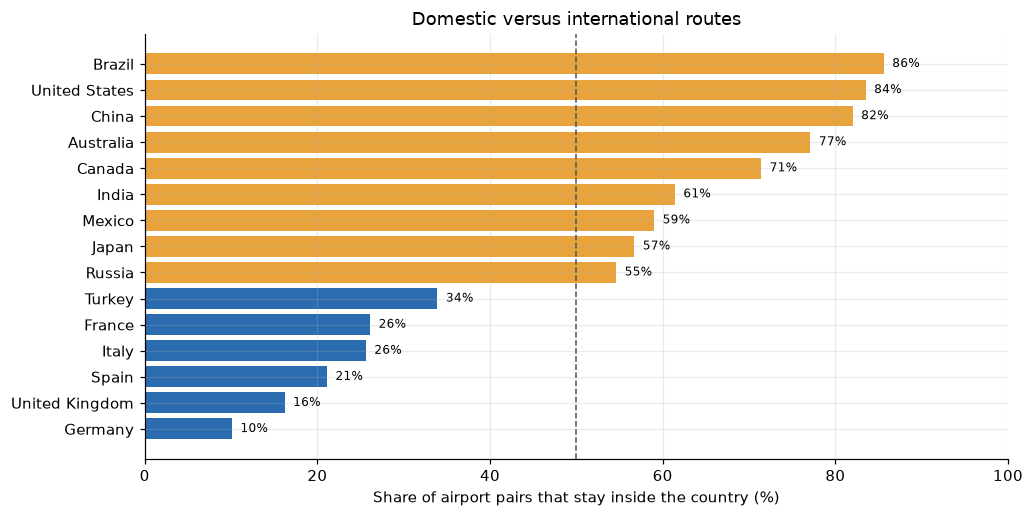

,country,airport_pairs,domestic_pct
0,Brazil,829,85.6
1,United States,6528,83.5
2,China,3316,82.0
3,Australia,572,77.1
4,Canada,1159,71.4
5,India,621,61.4
6,Mexico,546,59.0
7,Japan,617,56.7
8,Russia,1288,54.6
9,Turkey,635,33.9


In [6]:
domestic = q("""
WITH l AS (
    SELECT DISTINCT r.src, r.dst, a.country AS from_country, b.country AS to_country
    FROM routes r
    JOIN airports a ON a.iata = r.src
    JOIN airports b ON b.iata = r.dst
)
SELECT from_country AS country,
       COUNT(*)                                                       AS airport_pairs,
       ROUND(100.0 * SUM(from_country = to_country) / COUNT(*), 1)    AS domestic_pct
FROM l
GROUP BY from_country
HAVING COUNT(*) >= 500
ORDER BY domestic_pct DESC
""")

d = domestic.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(d.country, d.domestic_pct, color=[AMBER if v >= 50 else BLUE for v in d.domestic_pct])
for y, v in enumerate(d.domestic_pct):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8)
ax.axvline(50, color="#4a5568", ls="--", lw=1)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of airport pairs that stay inside the country (%)")
ax.set_title("Domestic versus international routes")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

domestic

## 5. How far do the routes go?

The great-circle distance between two airports comes from the **haversine formula** (the spherical law of cosines) written directly in SQL, using the `sin`, `cos`, `acos` and `radians` functions that SQLite provides. Distances are put into 500 km bands with an integer division; a running `SUM()` gives the cumulative share.

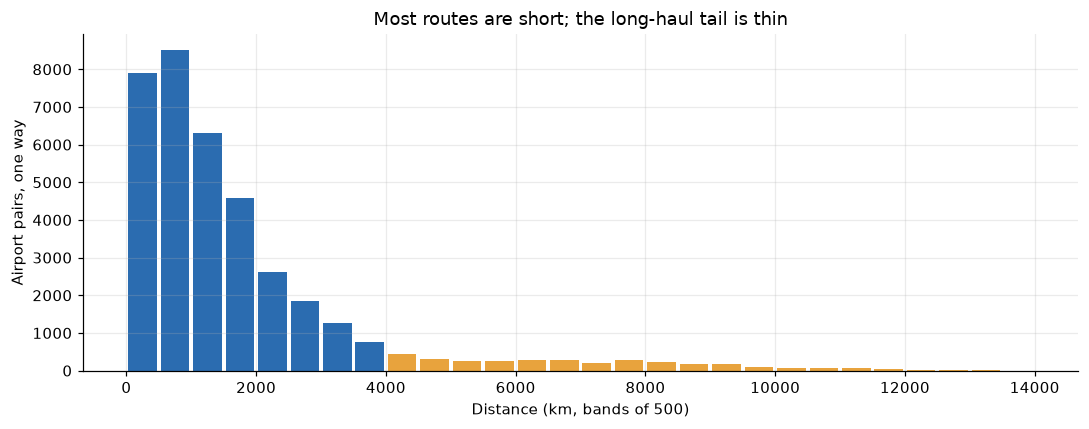

,from_km,pairs,pct,cumulative_pct
0,0+,7901,21.3,21.3
1,500+,8507,23.0,44.3
2,1000+,6300,17.0,61.3
3,1500+,4571,12.3,73.6
4,2000+,2608,7.0,80.7
5,2500+,1845,5.0,85.7
6,3000+,1258,3.4,89.1
7,3500+,771,2.1,91.1
8,4000+,429,1.2,92.3
9,4500+,313,0.8,93.1


In [7]:
bands = q("""
WITH l AS (
    SELECT DISTINCT r.src, r.dst, 6371 * acos(MIN(1.0, MAX(-1.0, sin(radians(a.lat)) * sin(radians(b.lat)) + cos(radians(a.lat)) * cos(radians(b.lat)) * cos(radians(b.lon - a.lon))))) AS km
    FROM routes r
    JOIN airports a ON a.iata = r.src
    JOIN airports b ON b.iata = r.dst
)
SELECT CAST(km / 500 AS INT) * 500                                                AS from_km,
       COUNT(*)                                                                    AS pairs,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                          AS pct,
       ROUND(100.0 * SUM(COUNT(*)) OVER (ORDER BY CAST(km / 500 AS INT)) / SUM(COUNT(*)) OVER (), 1) AS cumulative_pct
FROM l
GROUP BY from_km
ORDER BY from_km
""")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(bands.from_km + 250, bands.pairs, width=440, color=[BLUE if k < 4000 else AMBER for k in bands.from_km])
ax.set_xlabel("Distance (km, bands of 500)")
ax.set_ylabel("Airport pairs, one way")
ax.set_title("Most routes are short; the long-haul tail is thin")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

bands.assign(from_km=bands.from_km.astype(str) + '+')

## 6. What are the longest routes?

The same distance expression. `MIN(src, dst)` and `MAX(src, dst)` give every pair one canonical direction, so a route flown only one way is not lost.

In [8]:
longest = q("""
WITH pairs AS (
    SELECT DISTINCT MIN(src, dst) AS src, MAX(src, dst) AS dst FROM routes
)
SELECT r.src, r.dst, a.city AS from_city, b.city AS to_city, ROUND(6371 * acos(MIN(1.0, MAX(-1.0, sin(radians(a.lat)) * sin(radians(b.lat)) + cos(radians(a.lat)) * cos(radians(b.lat)) * cos(radians(b.lon - a.lon)))))) AS km
FROM pairs r
JOIN airports a ON a.iata = r.src
JOIN airports b ON b.iata = r.dst
ORDER BY km DESC
LIMIT 8
""")

longest

,src,dst,from_city,to_city,km
0,DFW,SYD,Dallas-Fort Worth,Sydney,13808.0
1,ATL,JNB,Atlanta,Johannesburg,13583.0
2,DXB,LAX,Dubai,Los Angeles,13400.0
3,JED,LAX,Jeddah,Los Angeles,13390.0
4,BNE,DFW,Brisbane,Dallas-Fort Worth,13365.0
5,DXB,IAH,Dubai,Houston,13125.0
6,DXB,SFO,Dubai,San Francisco,13020.0
7,HKG,JFK,Hong Kong,New York,12970.0


## 7. Hub airlines and point-to-point airlines

Per airline: routes, airports served, the average distance, and the share of its routes that start at its single busiest airport (`ROW_NUMBER()` per airline). A high share means a hub-and-spoke network, a low one point-to-point flying. Two precautions in the query: only flights an airline operates itself are used (codeshare flights are marketed by one airline and flown by another and would distort the hub), and only IATA codes carried by exactly one active airline are kept (the code VY belongs to both Vueling and Formosa, and the source links all VY routes to Formosa).

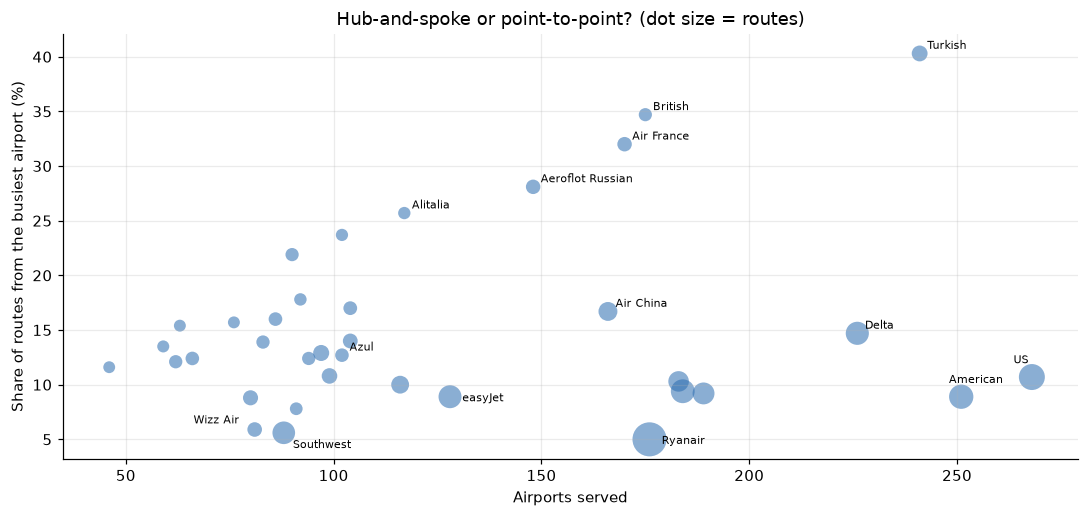

,airline,code,routes,airports_served,top_airport,top_airport_share_pct,avg_km
0,Ryanair,FR,2484,176,STN,5.0,1490.0
1,US Airways,US,1446,268,DFW,10.7,2405.0
2,American Airlines,AA,1265,251,CLT,8.9,2642.0
3,China Southern Airlines,CZ,1218,184,CAN,9.4,1408.0
4,Delta Air Lines,DL,1146,226,ATL,14.7,2630.0
5,easyJet,U2,1130,128,LGW,8.9,1400.0
6,Southwest Airlines,WN,1098,88,MDW,5.6,1405.0
7,China Eastern Airlines,MU,1028,189,PVG,9.2,1349.0
8,United Airlines,UA,905,183,EWR,10.3,3366.0
9,Air China,CA,766,166,PEK,16.7,1957.0


In [9]:
airlines = q("""
WITH names AS (
    SELECT iata, MIN(name) AS name
    FROM airlines
    WHERE active = 'Y' AND iata IS NOT NULL AND iata <> ''
    GROUP BY iata
    HAVING COUNT(*) = 1
),
leg AS (
    SELECT r.airline_code, r.src, 6371 * acos(MIN(1.0, MAX(-1.0, sin(radians(a.lat)) * sin(radians(b.lat)) + cos(radians(a.lat)) * cos(radians(b.lat)) * cos(radians(b.lon - a.lon))))) AS km
    FROM routes r
    JOIN airports a ON a.iata = r.src
    JOIN airports b ON b.iata = r.dst
    WHERE r.codeshare IS NULL AND r.airline_code IN (SELECT iata FROM names)
),
per_airport AS (
    SELECT airline_code, src, COUNT(*) AS n FROM leg GROUP BY airline_code, src
),
hub AS (
    SELECT airline_code, SUM(n) AS routes, COUNT(*) AS airports_served, MAX(n) AS top_n
    FROM per_airport GROUP BY airline_code
),
top AS (
    SELECT airline_code, src AS top_airport
    FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY airline_code ORDER BY n DESC, src) AS rk FROM per_airport)
    WHERE rk = 1
),
dist AS (
    SELECT airline_code, ROUND(AVG(km)) AS avg_km FROM leg GROUP BY airline_code
)
SELECT n.name AS airline, h.airline_code AS code, h.routes, h.airports_served, t.top_airport,
       ROUND(100.0 * h.top_n / h.routes, 1) AS top_airport_share_pct, d.avg_km
FROM hub h
JOIN names n ON n.iata = h.airline_code
JOIN top   t USING (airline_code)
JOIN dist  d USING (airline_code)
WHERE h.routes >= 300
ORDER BY h.routes DESC
""")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.scatter(airlines.airports_served, airlines.top_airport_share_pct, s=airlines.routes / 5, color=BLUE, alpha=0.55, edgecolor="none")
offsets = {"Southwest Airlines": (6, -10), "Wizz Air": (-40, 4), "Ryanair": (8, -3), "easyJet": (8, -3), "American Airlines": (-8, 9), "US Airways": (-12, 9)}
for _, r in airlines.iterrows():
    if r.top_airport_share_pct >= 25 or r.airline in offsets or r.airline in ("Delta Air Lines", "Air China", "Azul"):
        ax.annotate(r.airline.replace(" Airlines", "").replace(" Airways", "").replace(" Air Lines", "").replace(" Air Shuttle", ""),
                    (r.airports_served, r.top_airport_share_pct), xytext=offsets.get(r.airline, (5, 3)), textcoords="offset points", fontsize=7.5)
ax.set_xlabel("Airports served")
ax.set_ylabel("Share of routes from the busiest airport (%)")
ax.set_title("Hub-and-spoke or point-to-point? (dot size = routes)")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

airlines.head(12)

## 8. How many flights to anywhere? A recursive walk through the network

A **recursive CTE** starts at an airport and repeatedly adds every airport one more flight away; `UNION` (not `UNION ALL`) removes duplicate rows, which stops the walk from looping. `MIN(n)` per airport is its shortest number of flights, and a running `SUM()` gives the share of the network reached. Five starting points are compared in one query.

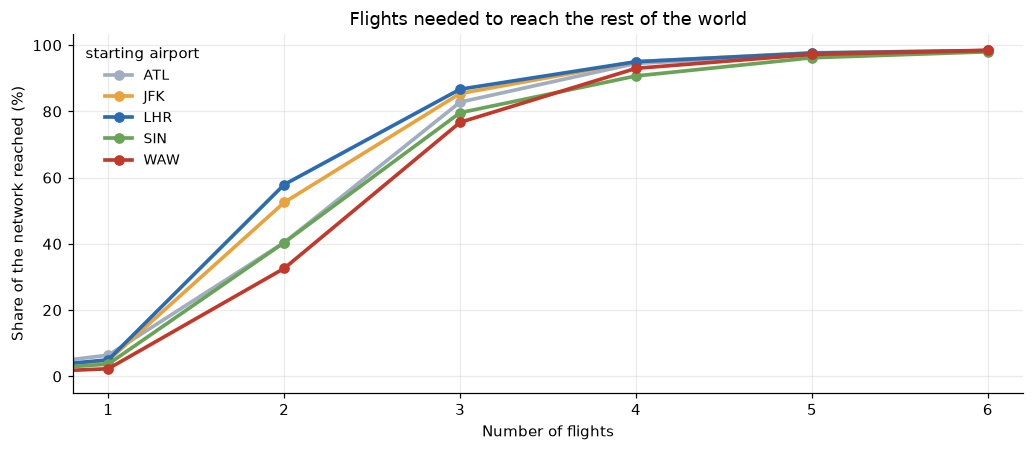

start,ATL,JFK,LHR,SIN,WAW
flights,,,,,
1,6.4,4.8,5.0,3.7,2.3
2,40.4,52.5,57.9,40.4,32.6
3,82.8,85.4,86.7,79.6,76.7
4,94.5,95.0,95.0,90.7,93.0


In [10]:
reach = q("""
WITH RECURSIVE starts(a) AS (
    VALUES ('WAW'), ('ATL'), ('LHR'), ('SIN'), ('JFK')
),
hops(start, airport, n) AS (
    SELECT a, a, 0 FROM starts
    UNION
    SELECT h.start, r.dst, h.n + 1
    FROM hops h
    JOIN routes r ON r.src = h.airport
    WHERE h.n < 6
),
best AS (
    SELECT start, airport, MIN(n) AS n FROM hops GROUP BY start, airport
),
network AS (
    SELECT COUNT(*) AS airports FROM (SELECT src FROM routes UNION SELECT dst FROM routes)
)
SELECT start, n AS flights, COUNT(*) AS new_airports,
       ROUND(100.0 * SUM(COUNT(*)) OVER (PARTITION BY start ORDER BY n) / (SELECT airports FROM network), 1) AS reached_pct
FROM best
GROUP BY start, n
ORDER BY start, n
""")

fig, ax = plt.subplots(figsize=(9.5, 4.2))
colors = {"ATL": GREY, "JFK": AMBER, "LHR": BLUE, "SIN": "#68a357", "WAW": RED}
for start, d in reach.groupby("start"):
    ax.plot(d.flights, d.reached_pct, marker="o", lw=2.4, color=colors[start], label=start)
ax.set_xlim(0.8, 6.2)
ax.set_xlabel("Number of flights")
ax.set_ylabel("Share of the network reached (%)")
ax.legend(frameon=False, fontsize=9, title="starting airport")
ax.set_title("Flights needed to reach the rest of the world")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

reach[reach.flights.between(1, 4)].pivot(index='flights', columns='start', values='reached_pct')

## 9. The shortest itinerary from Warsaw

A breadth-first search finds each airport's shortest number of flights from Warsaw (`reach` and `best`). A second recursive CTE then walks **backwards** from ten far-away destinations: for each airport it picks one predecessor that is exactly one flight closer (`pred`) and builds the route as text with `||`.

In [11]:
itineraries = q("""
WITH RECURSIVE reach(airport, n) AS (
    SELECT 'WAW', 0
    UNION
    SELECT r.dst, h.n + 1 FROM reach h JOIN routes r ON r.src = h.airport WHERE h.n < 6
),
best AS (
    SELECT airport, MIN(n) AS n FROM reach GROUP BY airport
),
pred AS (
    SELECT r.dst AS airport, b.n + 1 AS n, MIN(r.src) AS src
    FROM routes r JOIN best b ON b.airport = r.src
    GROUP BY r.dst, b.n
),
target(airport) AS (
    VALUES ('IPC'), ('USH'), ('LYR'), ('PPT'), ('LXA'), ('ULN'), ('MLE'), ('KTM'), ('GUM'), ('HNL')
),
back(airport, n, flights, path) AS (
    SELECT b.airport, b.n, b.n, b.airport FROM best b JOIN target t USING (airport)
    UNION ALL
    SELECT p.src, k.n - 1, k.flights, p.src || ' > ' || k.path
    FROM back k
    JOIN pred p ON p.airport = k.airport AND p.n = k.n
    WHERE k.n > 0
)
SELECT SUBSTR(path, -3) AS destination, a.city, a.country, flights, path AS itinerary
FROM back
JOIN airports a ON a.iata = SUBSTR(path, -3)
WHERE n = 0
ORDER BY flights DESC, destination
""")

itineraries

,destination,city,country,flights,itinerary
0,GUM,Agana,Guam,3,WAW > PEK > CTS > GUM
1,IPC,Easter Island,Chile,3,WAW > CDG > SCL > IPC
2,PPT,Papeete,French Polynesia,3,WAW > JFK > HNL > PPT
3,USH,Ushuaia,Argentina,3,WAW > AMS > EZE > USH
4,HNL,Honolulu,United States,2,WAW > JFK > HNL
5,KTM,Kathmandu,Nepal,2,WAW > DOH > KTM
6,LXA,Lhasa,China,2,WAW > PEK > LXA
7,LYR,Svalbard,Norway,2,WAW > OSL > LYR
8,MLE,Male,Maldives,2,WAW > DOH > MLE
9,ULN,Ulan Bator,Mongolia,2,WAW > PEK > ULN


## 10. The highest airports with scheduled flights

`RANK()` by altitude among airports that appear in the route list (a `UNION` of origins and destinations), converted from feet to metres.

In [12]:
highest = q("""
WITH served AS (
    SELECT src AS iata FROM routes UNION SELECT dst FROM routes
)
SELECT RANK() OVER (ORDER BY altitude_ft DESC) AS altitude_rank, name, city, country, altitude_ft, ROUND(altitude_ft * 0.3048) AS altitude_m
FROM airports
WHERE iata IN (SELECT iata FROM served)
ORDER BY altitude_ft DESC
LIMIT 8
""")

highest

,altitude_rank,name,city,country,altitude_ft,altitude_m
0,1,Daocheng Yading Airport,Daocheng,China,14472,4411.0
1,2,Qamdo Bangda Airport,Bangda,China,14219,4334.0
2,3,Kangding Airport,Kangding,China,14042,4280.0
3,4,Ngari Gunsa Airport,Shiquanhe,China,14022,4274.0
4,5,El Alto International Airport,La Paz,Bolivia,13355,4071.0
5,6,Capitan Nicolas Rojas Airport,Potosi,Bolivia,12913,3936.0
6,7,Yushu Batang Airport,Yushu,China,12816,3906.0
7,8,Inca Manco Capac International Airport,Juliaca,Peru,12552,3826.0


## 11. How complete is the data?

A last query audits the database itself with correlated `NOT EXISTS` subqueries: airport pairs that have no return flight, airports that appear in no route at all, routes without an airline id, and routes that point at an airport that is not in the airport table.

In [13]:
audit = q("""
WITH p AS (
    SELECT DISTINCT src, dst FROM routes
),
used AS (
    SELECT src AS iata FROM routes UNION SELECT dst FROM routes
)
SELECT (SELECT COUNT(*) FROM p)                                                                              AS airport_pairs,
       (SELECT COUNT(*) FROM p a WHERE NOT EXISTS (SELECT 1 FROM p b WHERE b.src = a.dst AND b.dst = a.src)) AS pairs_without_return,
       (SELECT COUNT(*) FROM airports WHERE iata IS NOT NULL)                                               AS airports_with_code,
       (SELECT COUNT(*) FROM airports WHERE iata IS NOT NULL AND iata NOT IN (SELECT iata FROM used))       AS airports_without_routes,
       (SELECT COUNT(*) FROM routes WHERE airline_id IS NULL)                                               AS routes_without_airline_id,
       (SELECT COUNT(*) FROM routes r
         WHERE NOT EXISTS (SELECT 1 FROM airports a WHERE a.iata = r.src)
            OR NOT EXISTS (SELECT 1 FROM airports a WHERE a.iata = r.dst))                                  AS routes_with_unknown_airport
""")

audit.T.rename(columns={0: 'value'})

,value
airport_pairs,37595
pairs_without_return,918
airports_with_code,6072
airports_without_routes,2810
routes_without_airline_id,479
routes_with_unknown_airport,729


## What the queries say

- **Europe's hubs lead, and Heathrow is not among the top ten.** Frankfurt has 239 non-stop destinations, Paris Charles de Gaulle 237, Amsterdam 232, Istanbul 227 and Atlanta 217. Eight of the fifteen best-connected airports are in Europe (counting Istanbul and Moscow), five in the United States and two in Asia and the Gulf (Beijing and Dubai). Heathrow, with 171, is only twelfth, behind Frankfurt, Munich and Moscow Domodedovo.
- **The network is extremely unequal.** The busiest 1% of airports (34 of 3,409 with departures) hold 15.5% of all airport pairs, the top 5% hold 45.1%, the top 10% 62.7% and the top 25% 82.6%. At the other end, 906 airports (27%) have a single destination, 1,949 (57%) have three or fewer, and only 64 have 100 or more; the average is 11.0.
- **Big countries fly at home, European ones do not.** The share of pairs that stay inside the country is 85.6% in Brazil, 83.5% in the United States, 82.0% in China, 77.1% in Australia and 71.4% in Canada, against 26.1% in France, 21.1% in Spain, 16.2% in the United Kingdom and 10.1% in Germany. Russia (54.6%), India (61.4%) and Japan (56.7%) sit in between.
- **Short routes dominate.** 44.3% of one-way airport pairs are shorter than 1,000 km, 73.6% shorter than 2,000 km and 89.1% shorter than 3,500 km. Pairs of 8,000 km or more are 2.6% of the total. The longest is Dallas-Fort Worth to Sydney at 13,808 km, followed by Atlanta to Johannesburg (13,583 km) and Dubai to Los Angeles (13,400 km).
- **Ryanair is the extreme of point-to-point; Turkish and British Airways are hubs.** Among the 36 airlines with at least 300 routes they operate themselves, Ryanair has the most (2,484 routes to 176 airports) and only 5.0% of them start at its busiest airport (Stansted); Southwest (5.6%) and Wizz Air (5.9%) are similar. Turkish Airlines has 40.3% of its routes from Istanbul, British Airways 34.7% from Heathrow and Air France 32.0% from Charles de Gaulle. American Airlines is large (1,265 routes, 251 airports) but spread over several hubs, so its busiest airport (Charlotte) has only 8.9%. The average route is 3,692 km for Air Canada and 3,589 km for British Airways, but 696 km for Azul.
- **A recursive walk shows how much a hub is worth.** Within two flights (one change) a passenger from Heathrow reaches 57.9% of the 3,425 airports in the network, from New York JFK 52.5%, from Atlanta and Singapore 40.4% and from Warsaw 32.6%. Within three flights it is 86.7%, 85.4%, 82.8%, 79.6% and 76.7%, and within four flights 90.7% to 95.0%. Atlanta has more direct destinations (217) than Heathrow (171) but reaches fewer airports in two flights, because its neighbours are mostly small American airports with few onward routes while Heathrow's neighbours are hubs.
- **Even remote places are about three flights from Warsaw.** The back-tracking query finds, among ten far-away destinations: Honolulu in 2 flights (via New York), Lhasa and Ulaanbaatar via Beijing, Kathmandu and the Maldives via Doha, Svalbard via Oslo, Easter Island in 3 (Paris and Santiago), Ushuaia in 3 (Amsterdam and Buenos Aires), Tahiti in 3 (New York and Honolulu) and Guam in 3 (Beijing and Sapporo). Where several shortest routes exist the query shows one of them.
- **The highest scheduled airports are on the Tibetan plateau.** Daocheng Yading in China is the highest at 4,411 m, and the first four are all Chinese. El Alto in La Paz (4,071 m) is the highest outside China.
- **The data has holes, and they matter.** Of 37,595 airport pairs, 918 (2.4%) have no flight back. Of 6,072 airports with a code, 2,810 (46%) appear in no route at all. 479 routes have no airline id and 729 touch an airport that is not in the airport list.

**What to be careful about.** This is a snapshot of about 2014 (the route file was last changed in 2017), so it shows a past network. Airport names come from a newer file than the routes, so a code that changed owner since then (Istanbul's IST) is labelled with the newer airport while its routes belong to the older one. IATA codes are shared between airlines, so the airline table keeps only codes with exactly one active airline and only flights the airline operates itself, but a few mislabelled codes can still slip through; read single airlines with that in mind. Distances are great-circle, not flight paths, and "routes" counts airline and airport pairs, not flights per day.